# UNI2 ablation, cross-section (A0–A3)

Same split, same UNI2 class token (1536-d), same three heads. The only change between rows is the loss and the spatial block:

| | loss | spatial |
| --- | --- | --- |
| A0 | legacy: 3 CE + L2→L1 NLL weight 2 | none |
| A1 | adjacent: L2→L1 NLL weight 2, plus NLL 0.5 / 0.5 and JS 0.1 / 0.1 | none |
| A2 | same as A1 | k=8 uniform mean of neighbor UNI2 vectors |
| A3 | same as A1 | same mean, multiplied by a learned gate |

2026.10.27: the cells below score the finished `paired_v2_seed42` retrain for A0–A3 (named-layer init, split-seed 42, L2→L1 NLL weight 2).

The number to compare is the **pooled out-of-fold (OOF) L2 macro AUROC** in `validation_internal_metrics.csv` (the log line `OOF L2 macro AUROC=`). The last epoch's `Val head macro-AUROC` is only the inner validation of the last fold.

| | pooled OOF L2 | mean of the five fold L2 AUROCs | best_mlp fold |
| --- | --- | --- | --- |
| A3 k=8 mean+gate | **0.8897** | 0.8805 | 0 |
| A2 k=8 mean | 0.8894 | 0.8798 | 1 |
| A1 adjacent, no spatial | 0.8601 | 0.8468 | 0 |
| A0 legacy, no spatial | 0.8580 | 0.8453 | 0 |

A3 is the highest finished weight in this retrain. Its margin over A2 is 0.0003.

2026.10.26 morning, before this retrain (A1–A3 used L2→L1 NLL weight 1): A3 0.8907 > A2 0.8884 > A0 0.8590 ≈ A1 0.8580. Those A0–A3 checkpoints were removed.

- OOF（out-of-fold）：cross-section 五折里，每张切片只被留出一次。一个细胞的概率来自没见过它所在切片的那一折模型。5,627,071 个细胞各有一份这样的预测。
- pooled：这 562 万份预测先拼成一张表，再算一次 AUROC。A0 的这个数是 0.8580。五折各自的 L2 AUROC 再取平均是另一件事，A0 的折均值是 0.8453。折均值把五份切片子集看成同等重要；pooled 先按细胞放在一起，大折占的细胞更多。
- L2：最细的那一头，20 类（Tumor、CD8 T、Fibroblast、Neural 等）。L12 是 8 类，L1 是 5 类，都不是这个数。
- macro AUROC：每一类做一次 one-vs-rest AUROC，再对能算的类取算术平均。Neural 大约 1.1 万个细胞，Tumor 大约 84 万个，在这个平均里权重一样。某一类没有正例或没有负例时，这一类不进入平均。

Helpers live in `pred_statistic_visual.py`. The published UNI cross-section vs cross-celltype figures stay in `4_Pred_statistic_visual_pancancer_all.ipynb`.


In [1]:
import sys
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
# 2026.10.26, portable repo / 保留原路径记录，优先环境变量及当前 checkout
if os.environ.get("HIST2PHENO_REPO"):
    REPO = Path(os.environ["HIST2PHENO_REPO"]).expanduser().resolve()
else:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "code" / "PanCancer").is_dir():
            REPO = candidate
            break
PKG = REPO / "code" / "Hist2Pheno_pkg"
if str(PKG) not in sys.path:
    sys.path.insert(0, str(PKG))
PAN = REPO / "code" / "PanCancer"
if str(PAN) not in sys.path:
    sys.path.insert(0, str(PAN))


,arch,label,best_mlp,n_fold_ckpt,oof_npz,pooled_oof
0,A0,A0 legacy,True,5,True,True
1,A1,A1 adjacent,True,5,True,True
2,A2,A2 k8 mean,True,5,True,True
3,A3,A3 k8 mean+gate,True,5,True,True


,arch,label,n_cells,n_folds,best_fold,oof_l2_macro_auc,cv_l2_macro_f1_mean
0,A0,A0 legacy,5627071,5,0,0.858018,0.228673
1,A1,A1 adjacent,5627071,5,0,0.860105,0.230305
2,A2,A2 k8 mean,5627071,5,1,0.889384,0.294063
3,A3,A3 k8 mean+gate,5627071,5,0,0.889730,0.301343


Pooled OOF L2 macro AUROC  A0=0.8580  vs A0 +0.0000
Pooled OOF L2 macro AUROC  A1=0.8601  vs A0 +0.0021
Pooled OOF L2 macro AUROC  A2=0.8894  vs A0 +0.0314
Pooled OOF L2 macro AUROC  A3=0.8897  vs A0 +0.0317


,fold,A0_L2_auc,A0_L12_auc,A0_L1_auc,A0_sum_auc,A0_L2_f1,A0_L12_f1,A0_L1_f1,A0_best_epoch,A1_L2_auc,...,A2_L1_f1,A2_best_epoch,A3_L2_auc,A3_L12_auc,A3_L1_auc,A3_sum_auc,A3_L2_f1,A3_L12_f1,A3_L1_f1,A3_best_epoch
0,0,0.869301,0.805577,0.798371,2.473250,0.254569,0.333570,0.373787,13,0.869616,...,0.414298,14,0.894979,0.835299,0.833557,2.563835,0.305588,0.386371,0.417483,14
1,1,0.854619,0.792985,0.804485,2.452089,0.237872,0.326102,0.348790,11,0.858290,...,0.414823,9,0.884662,0.830346,0.838853,2.553861,0.294744,0.375082,0.406319,10
2,2,0.829685,0.785681,0.783557,2.398924,0.202356,0.318603,0.325103,12,0.830576,...,0.372705,5,0.867261,0.828560,0.828501,2.524321,0.253729,0.376239,0.376991,9
3,3,0.842017,0.784234,0.758728,2.384980,0.226457,0.395177,0.327658,10,0.842636,...,0.495853,12,0.879310,0.828526,0.808220,2.516057,0.345680,0.484726,0.506642,10
4,4,0.831007,0.768338,0.748274,2.347619,0.222110,0.386156,0.319785,7,0.832697,...,0.392796,12,0.876192,0.818052,0.801449,2.495693,0.306976,0.475036,0.405095,12


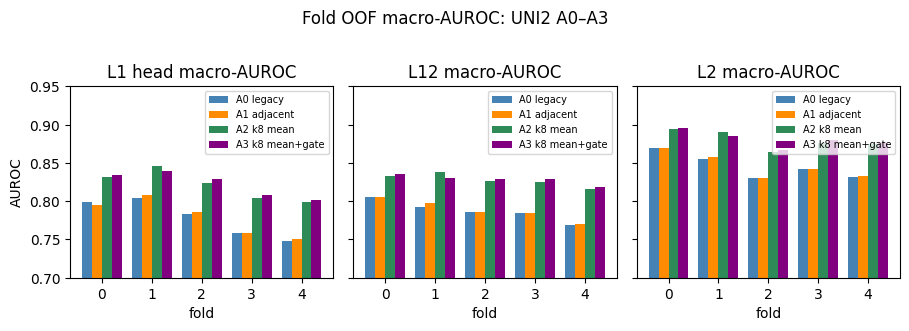

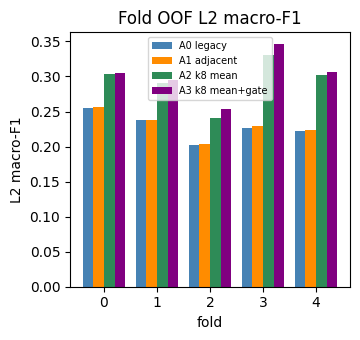

A0 OOF L2 ROC /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/result_uni2_A0_legacy_nospatial_paired_v2_seed42/roc_internal_level2_oof.png


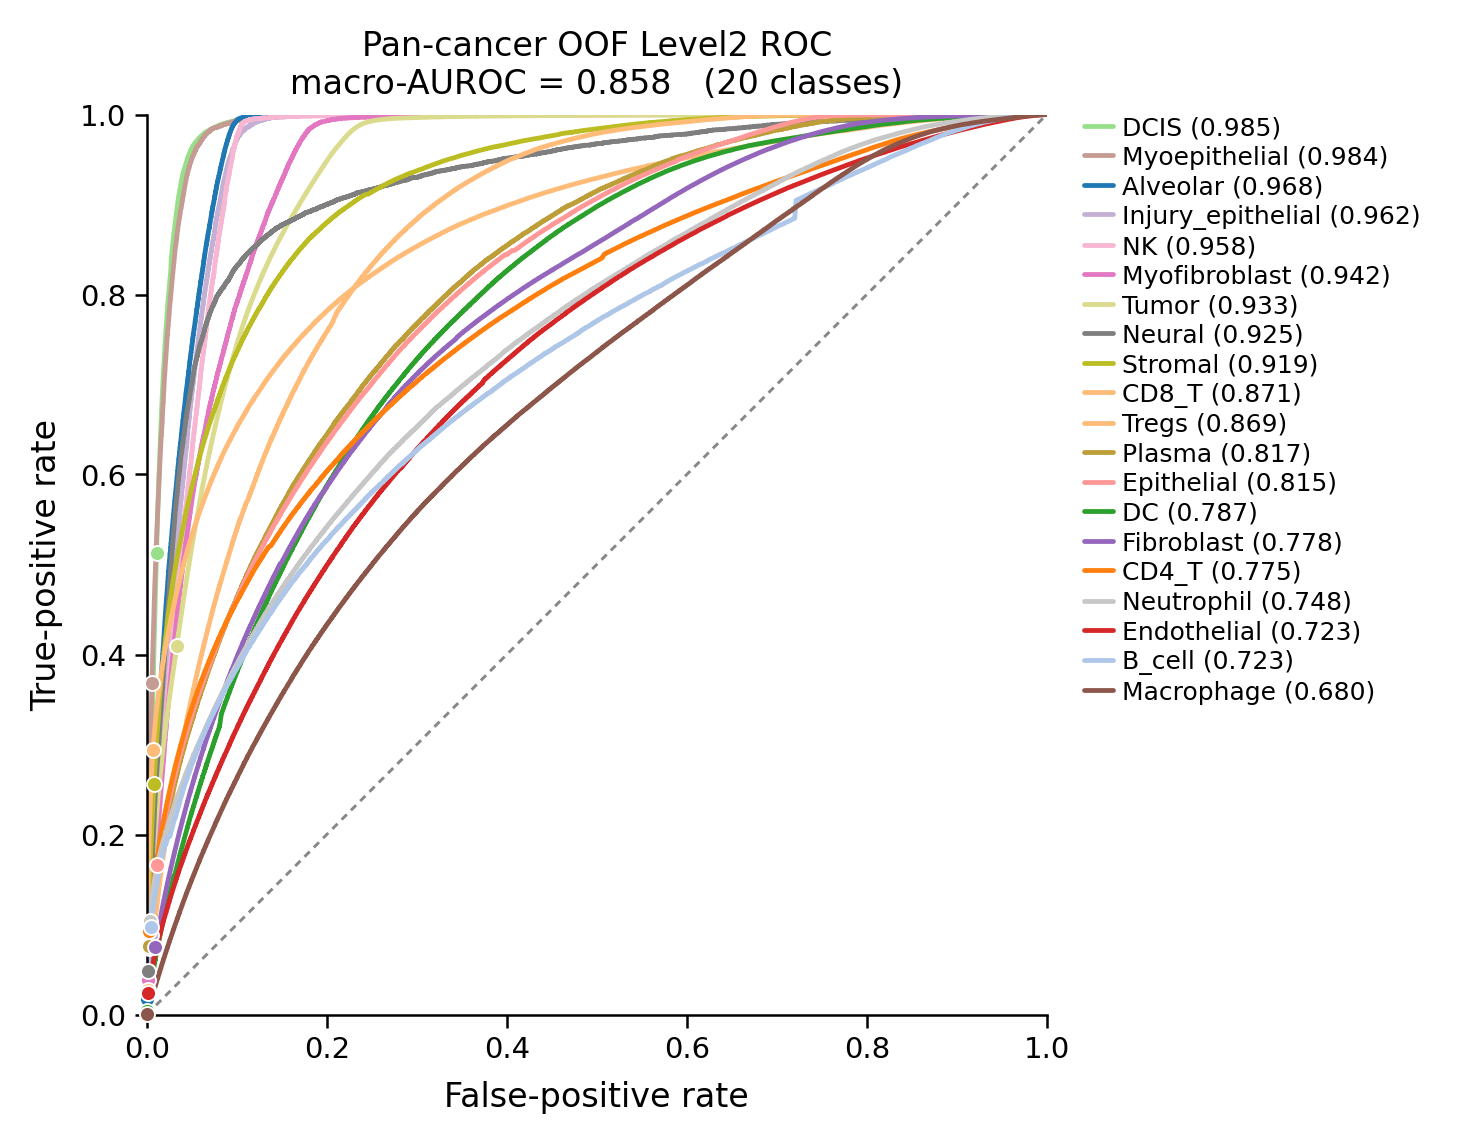

A0 OOF L2 confusion /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/result_uni2_A0_legacy_nospatial_paired_v2_seed42/conf_matrix_level2.png


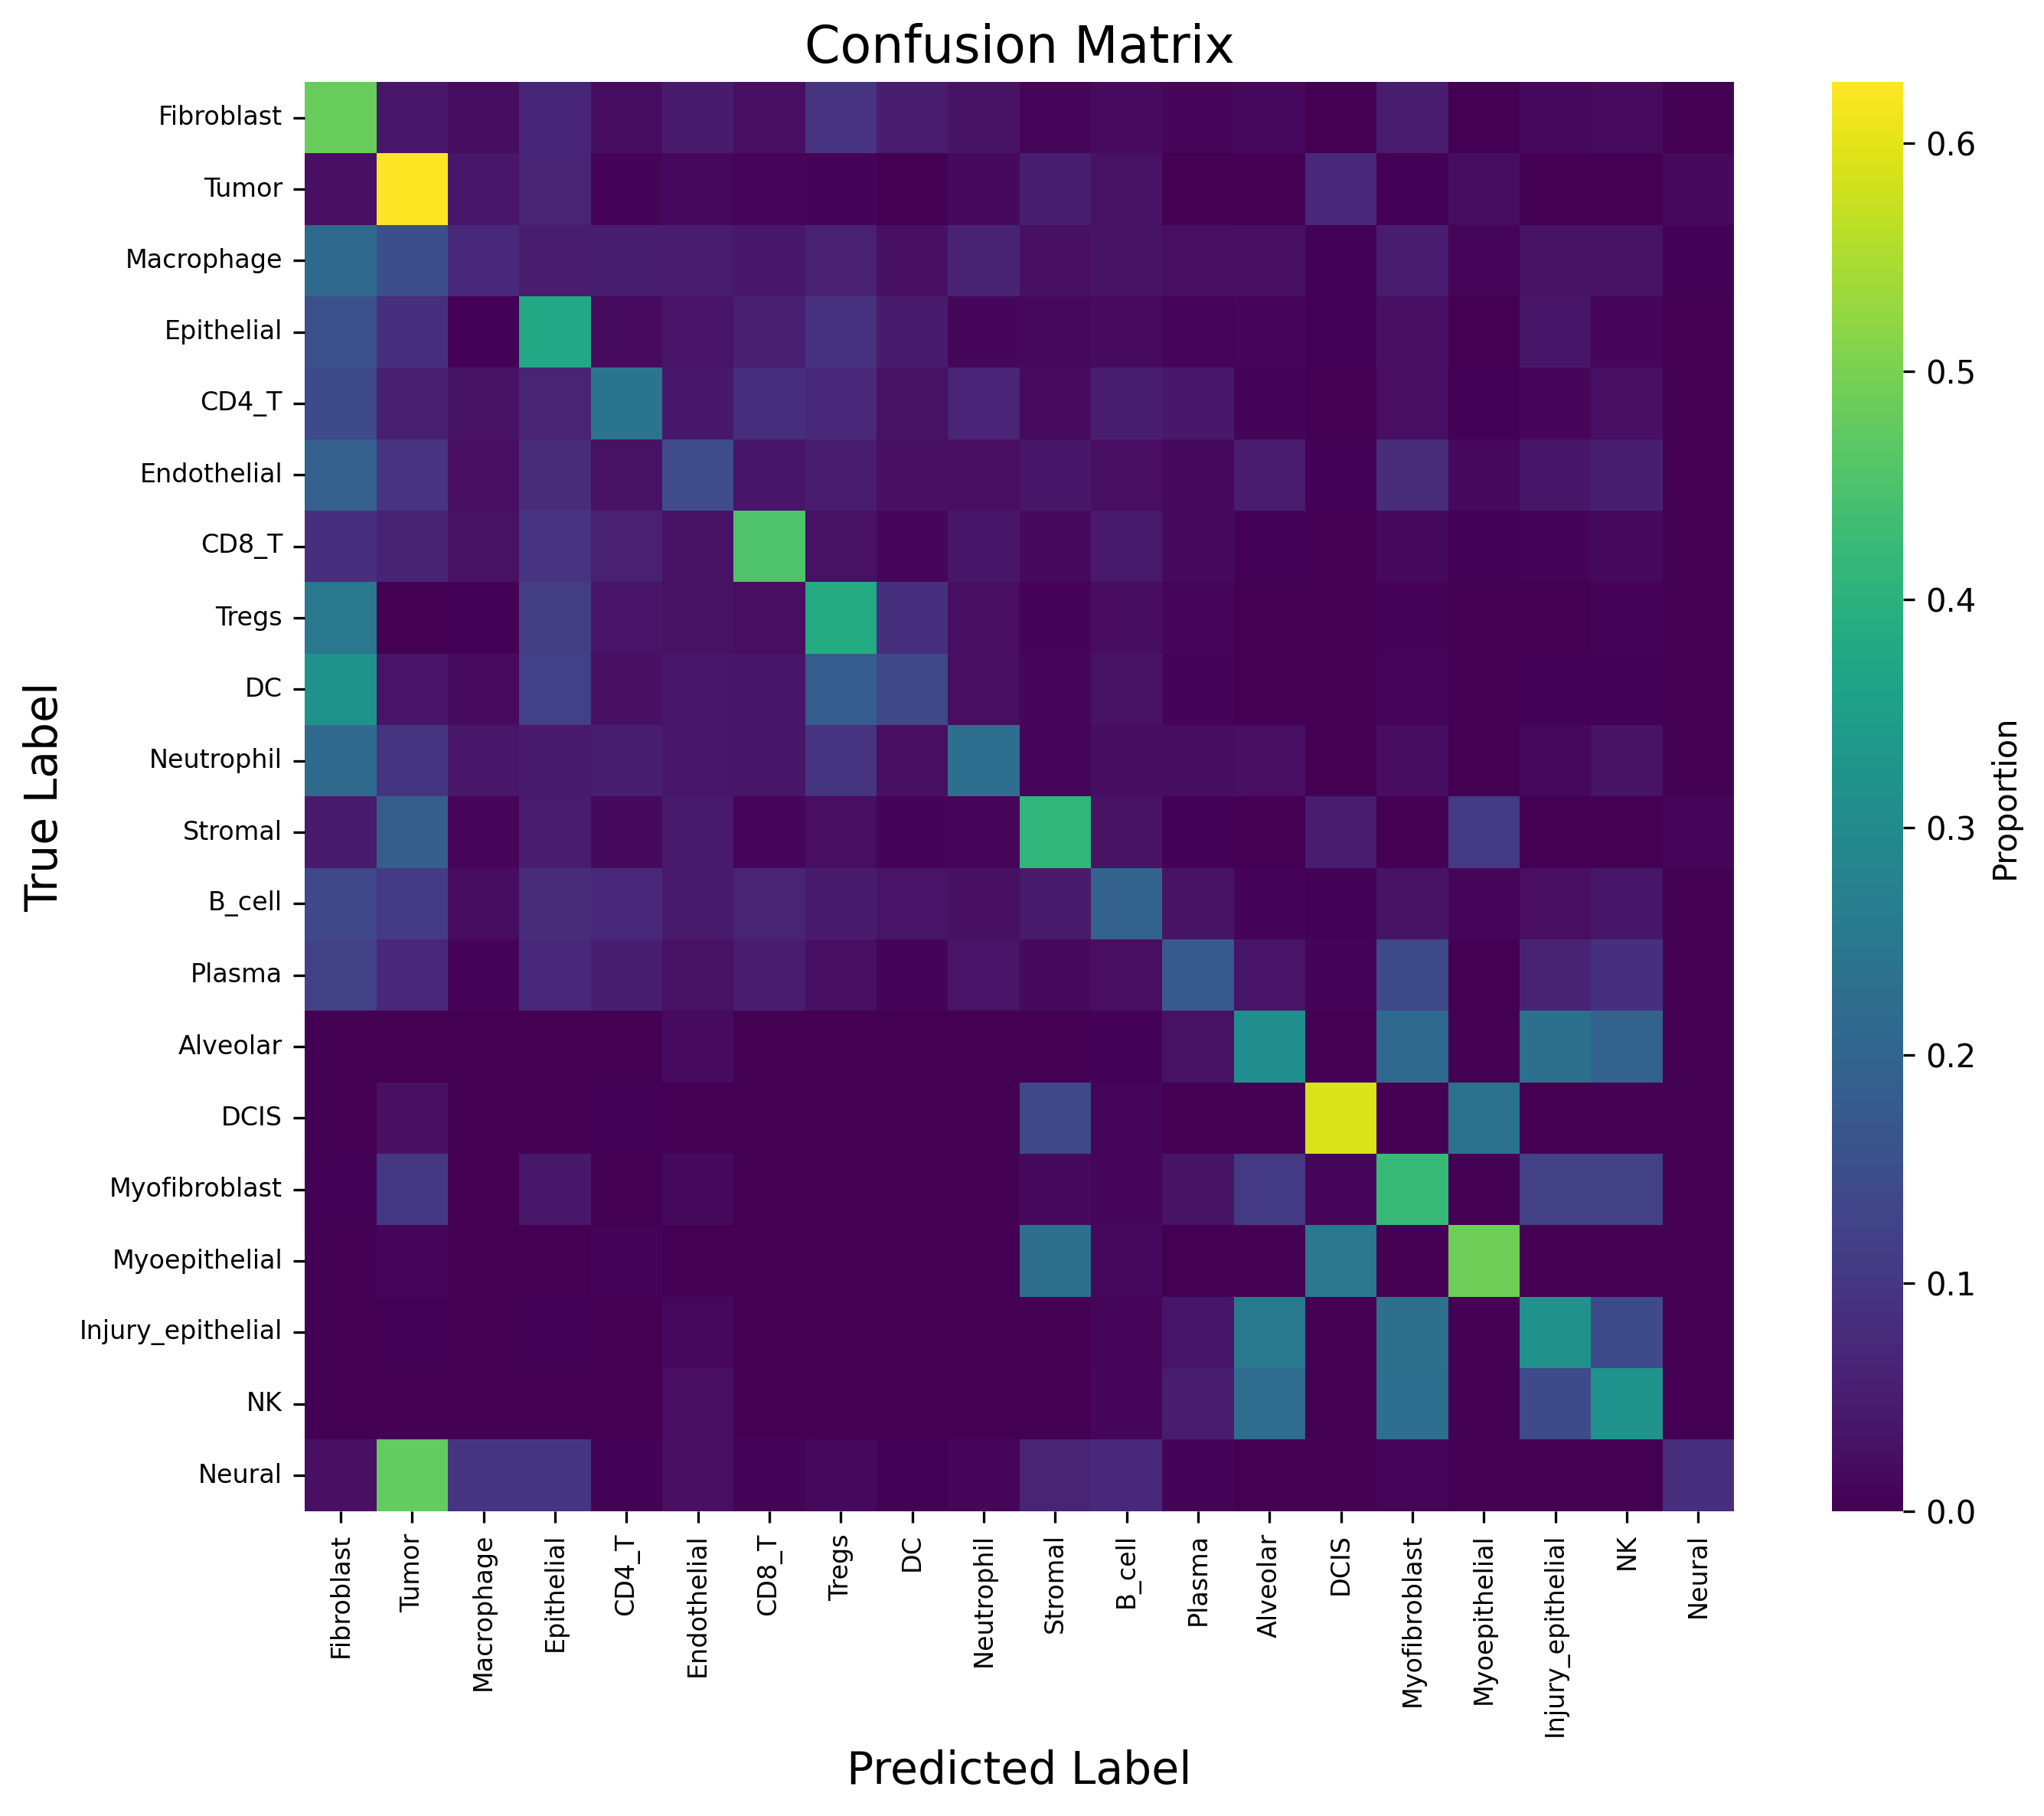

A1 OOF L2 ROC /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/result_uni2_A1_adjacent_nospatial_paired_v2_seed42/roc_internal_level2_oof.png


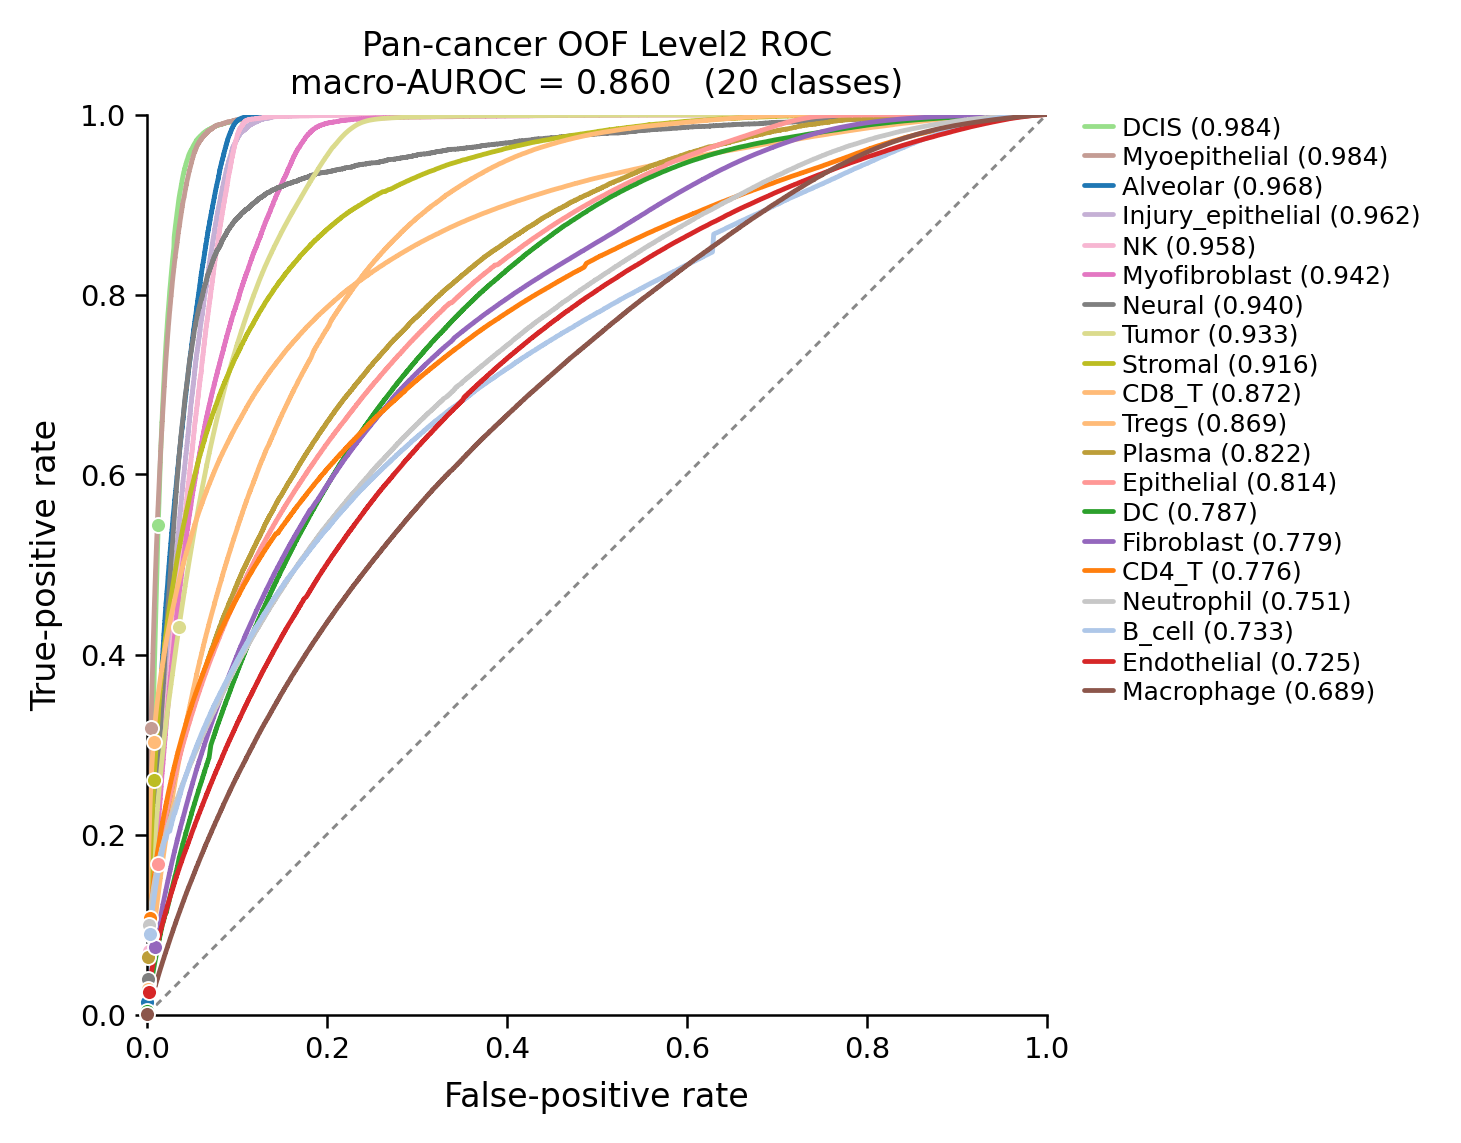

A1 OOF L2 confusion /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/result_uni2_A1_adjacent_nospatial_paired_v2_seed42/conf_matrix_level2.png


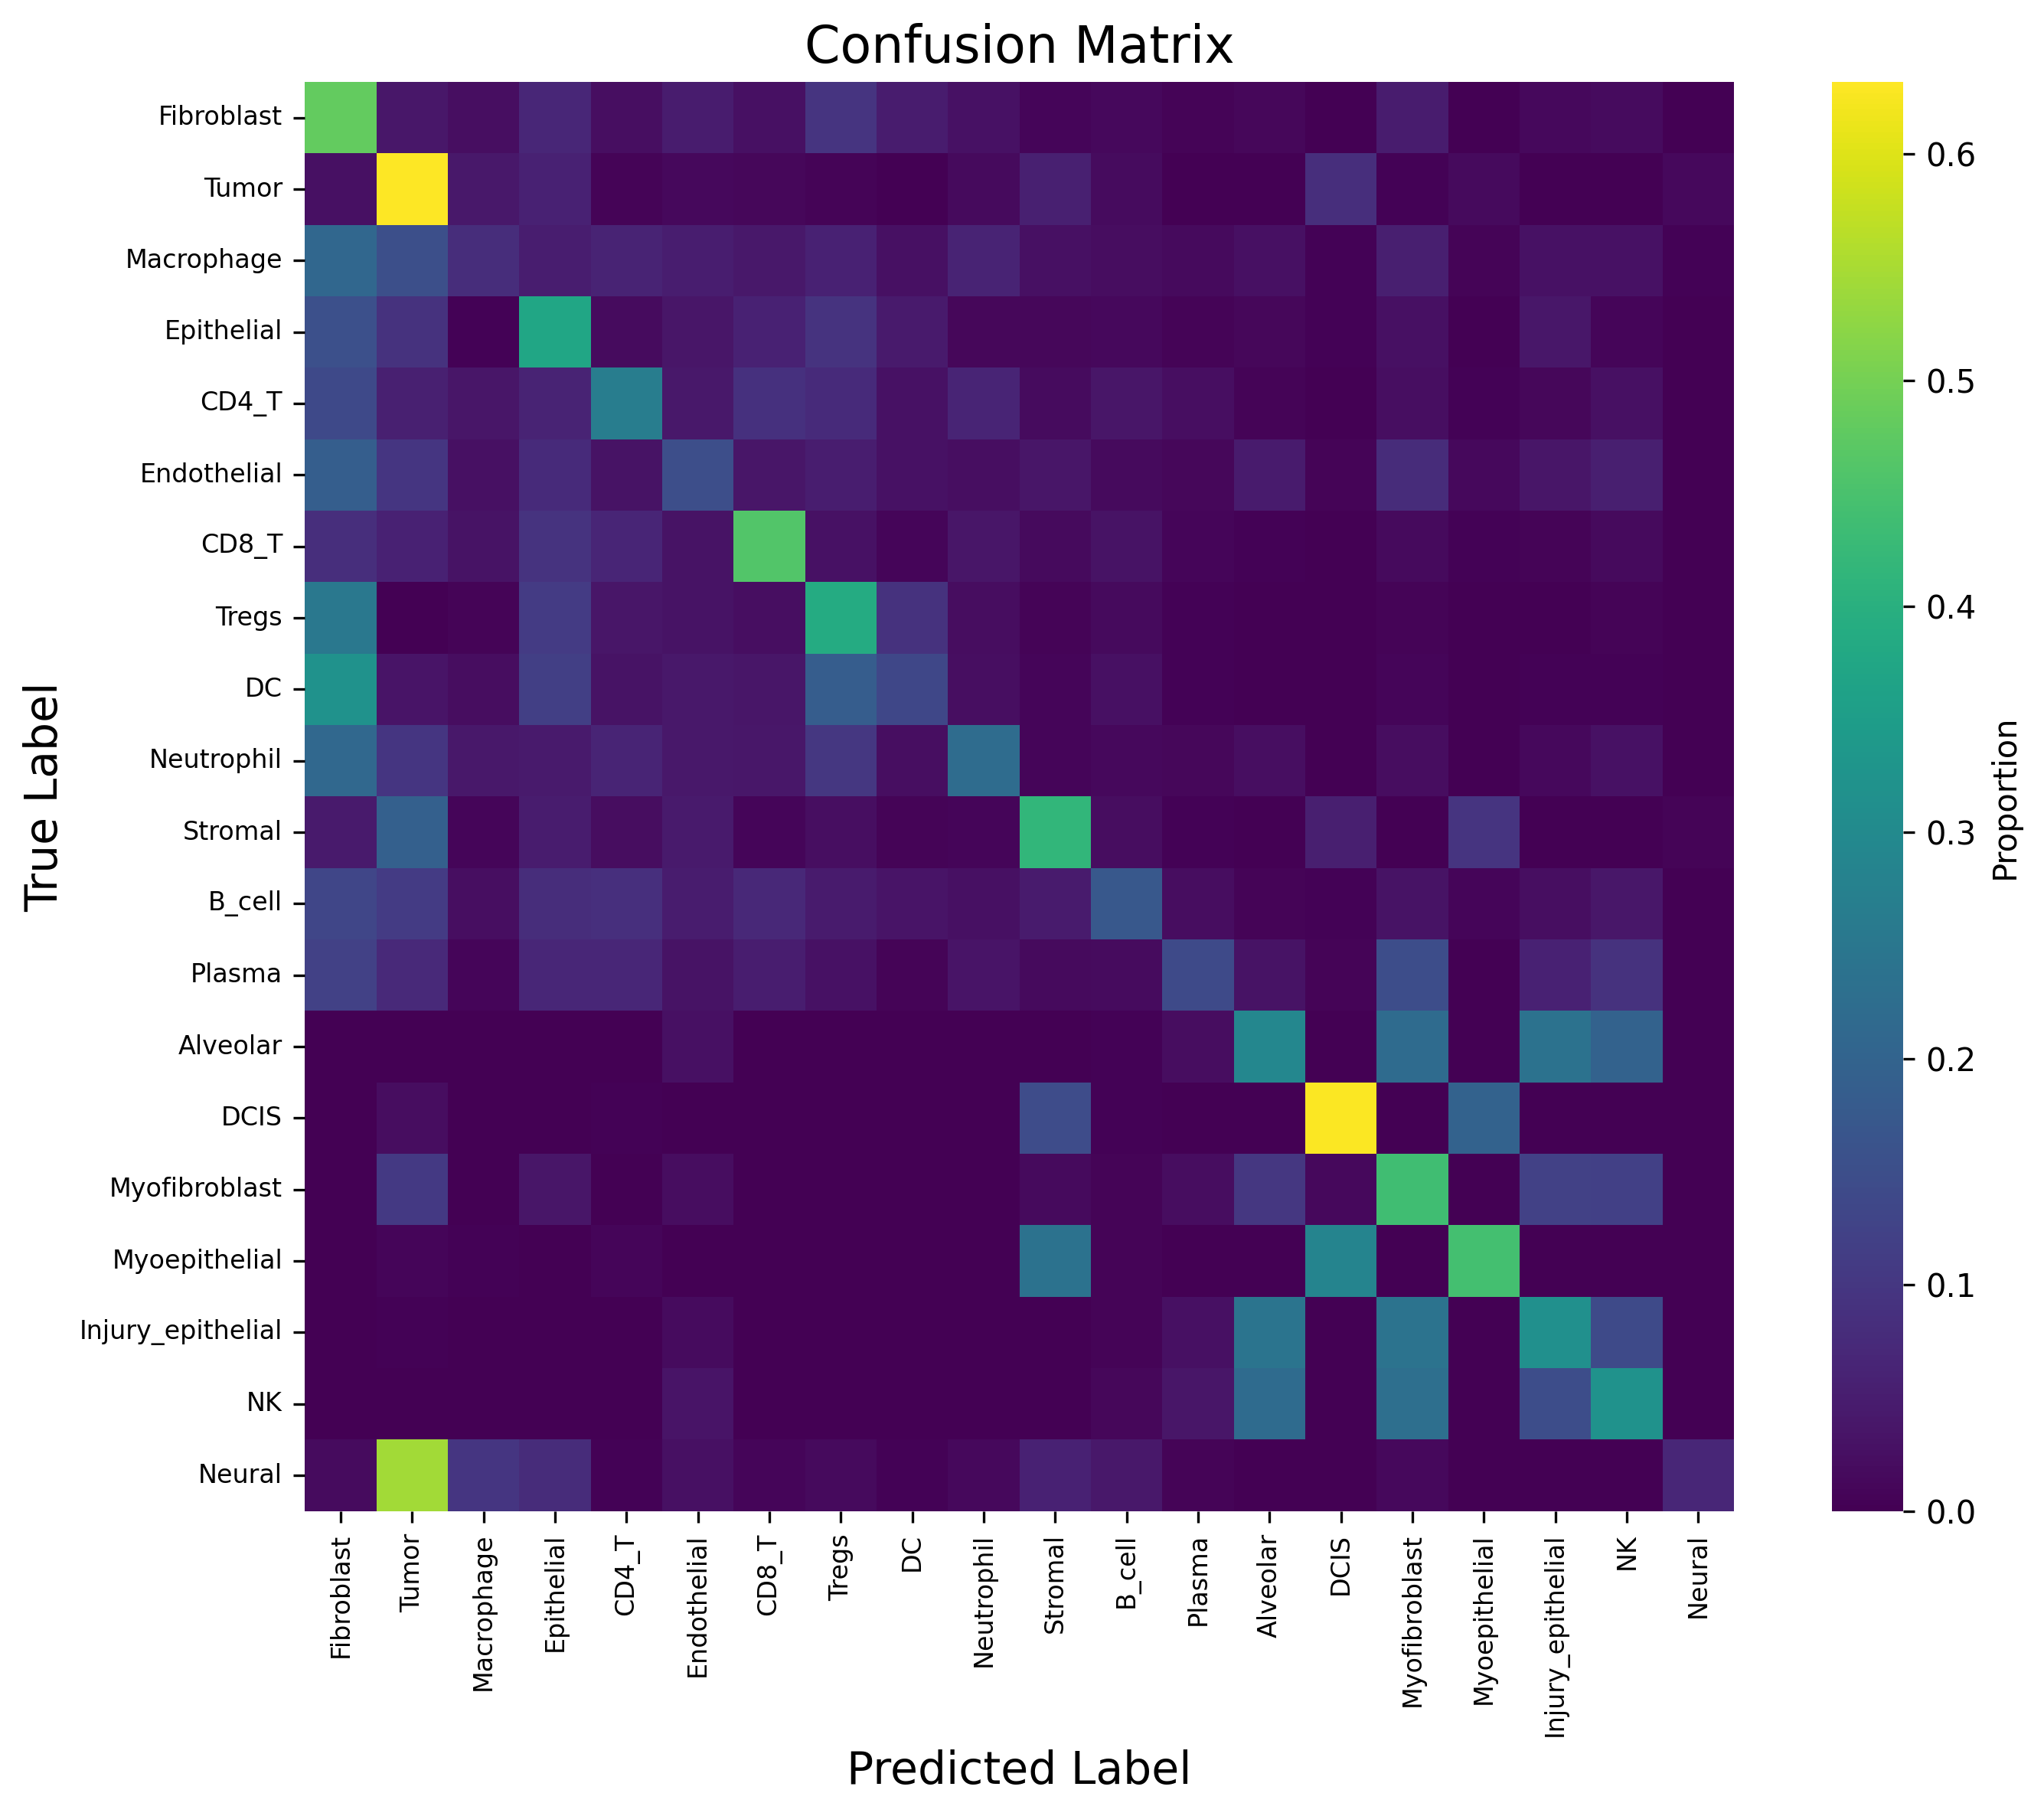

A2 OOF L2 ROC /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/roc_internal_level2_oof.png


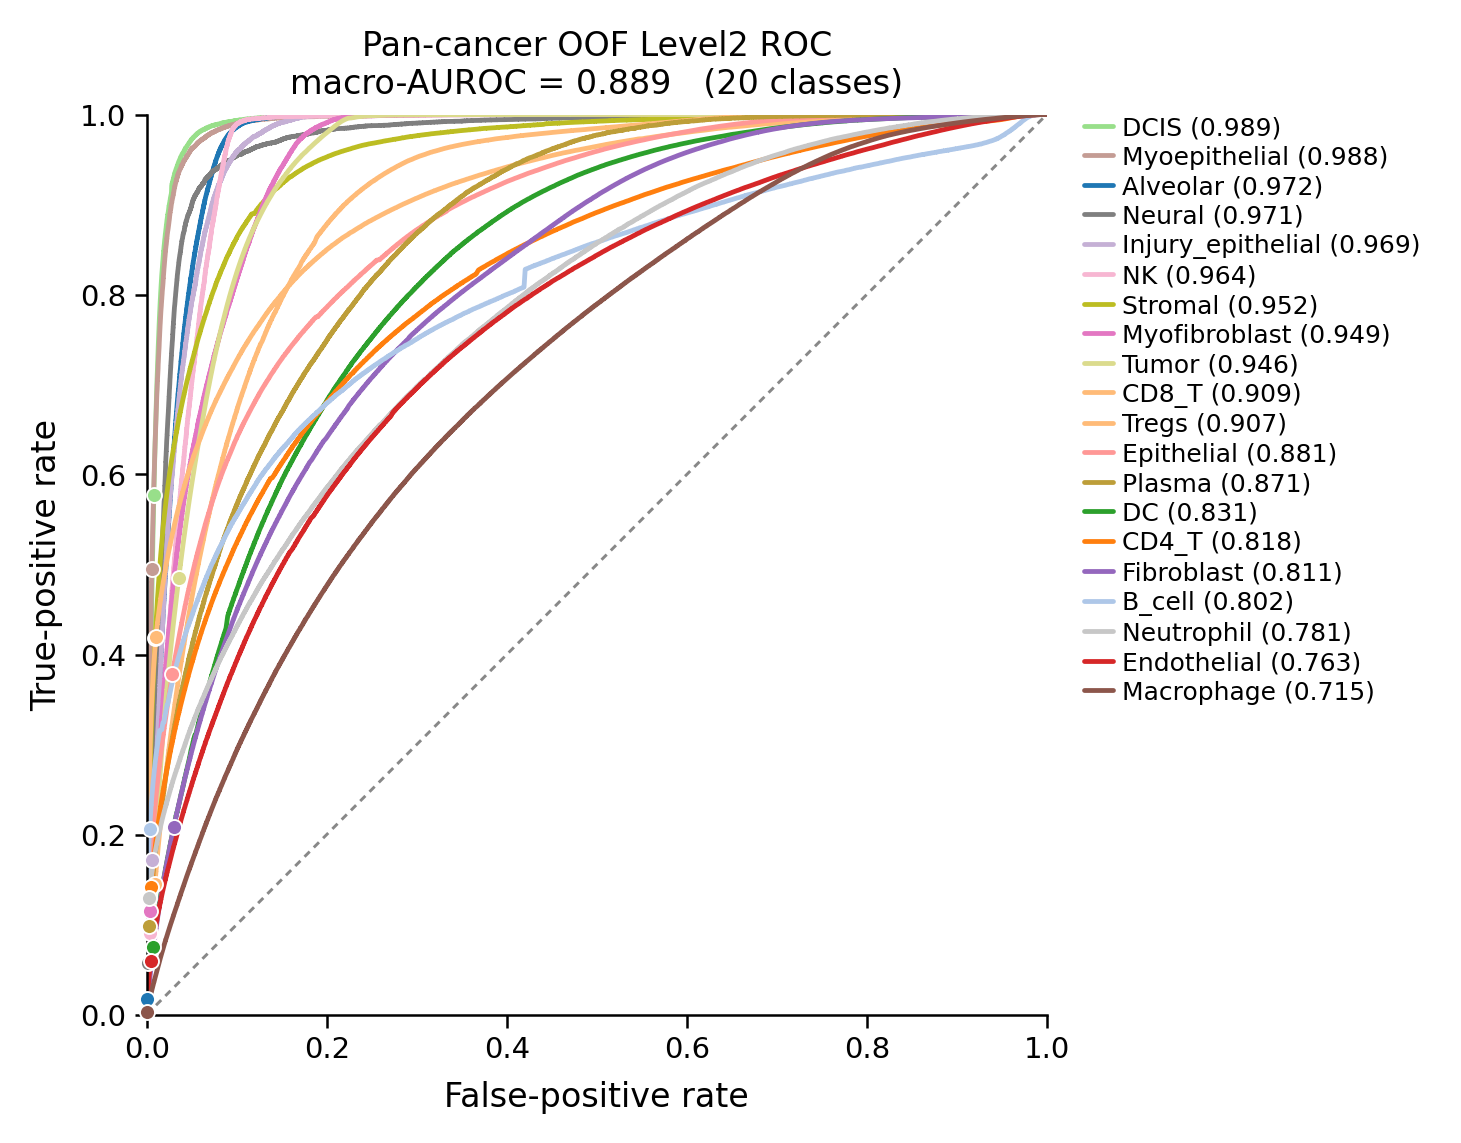

A2 OOF L2 confusion /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/conf_matrix_level2.png


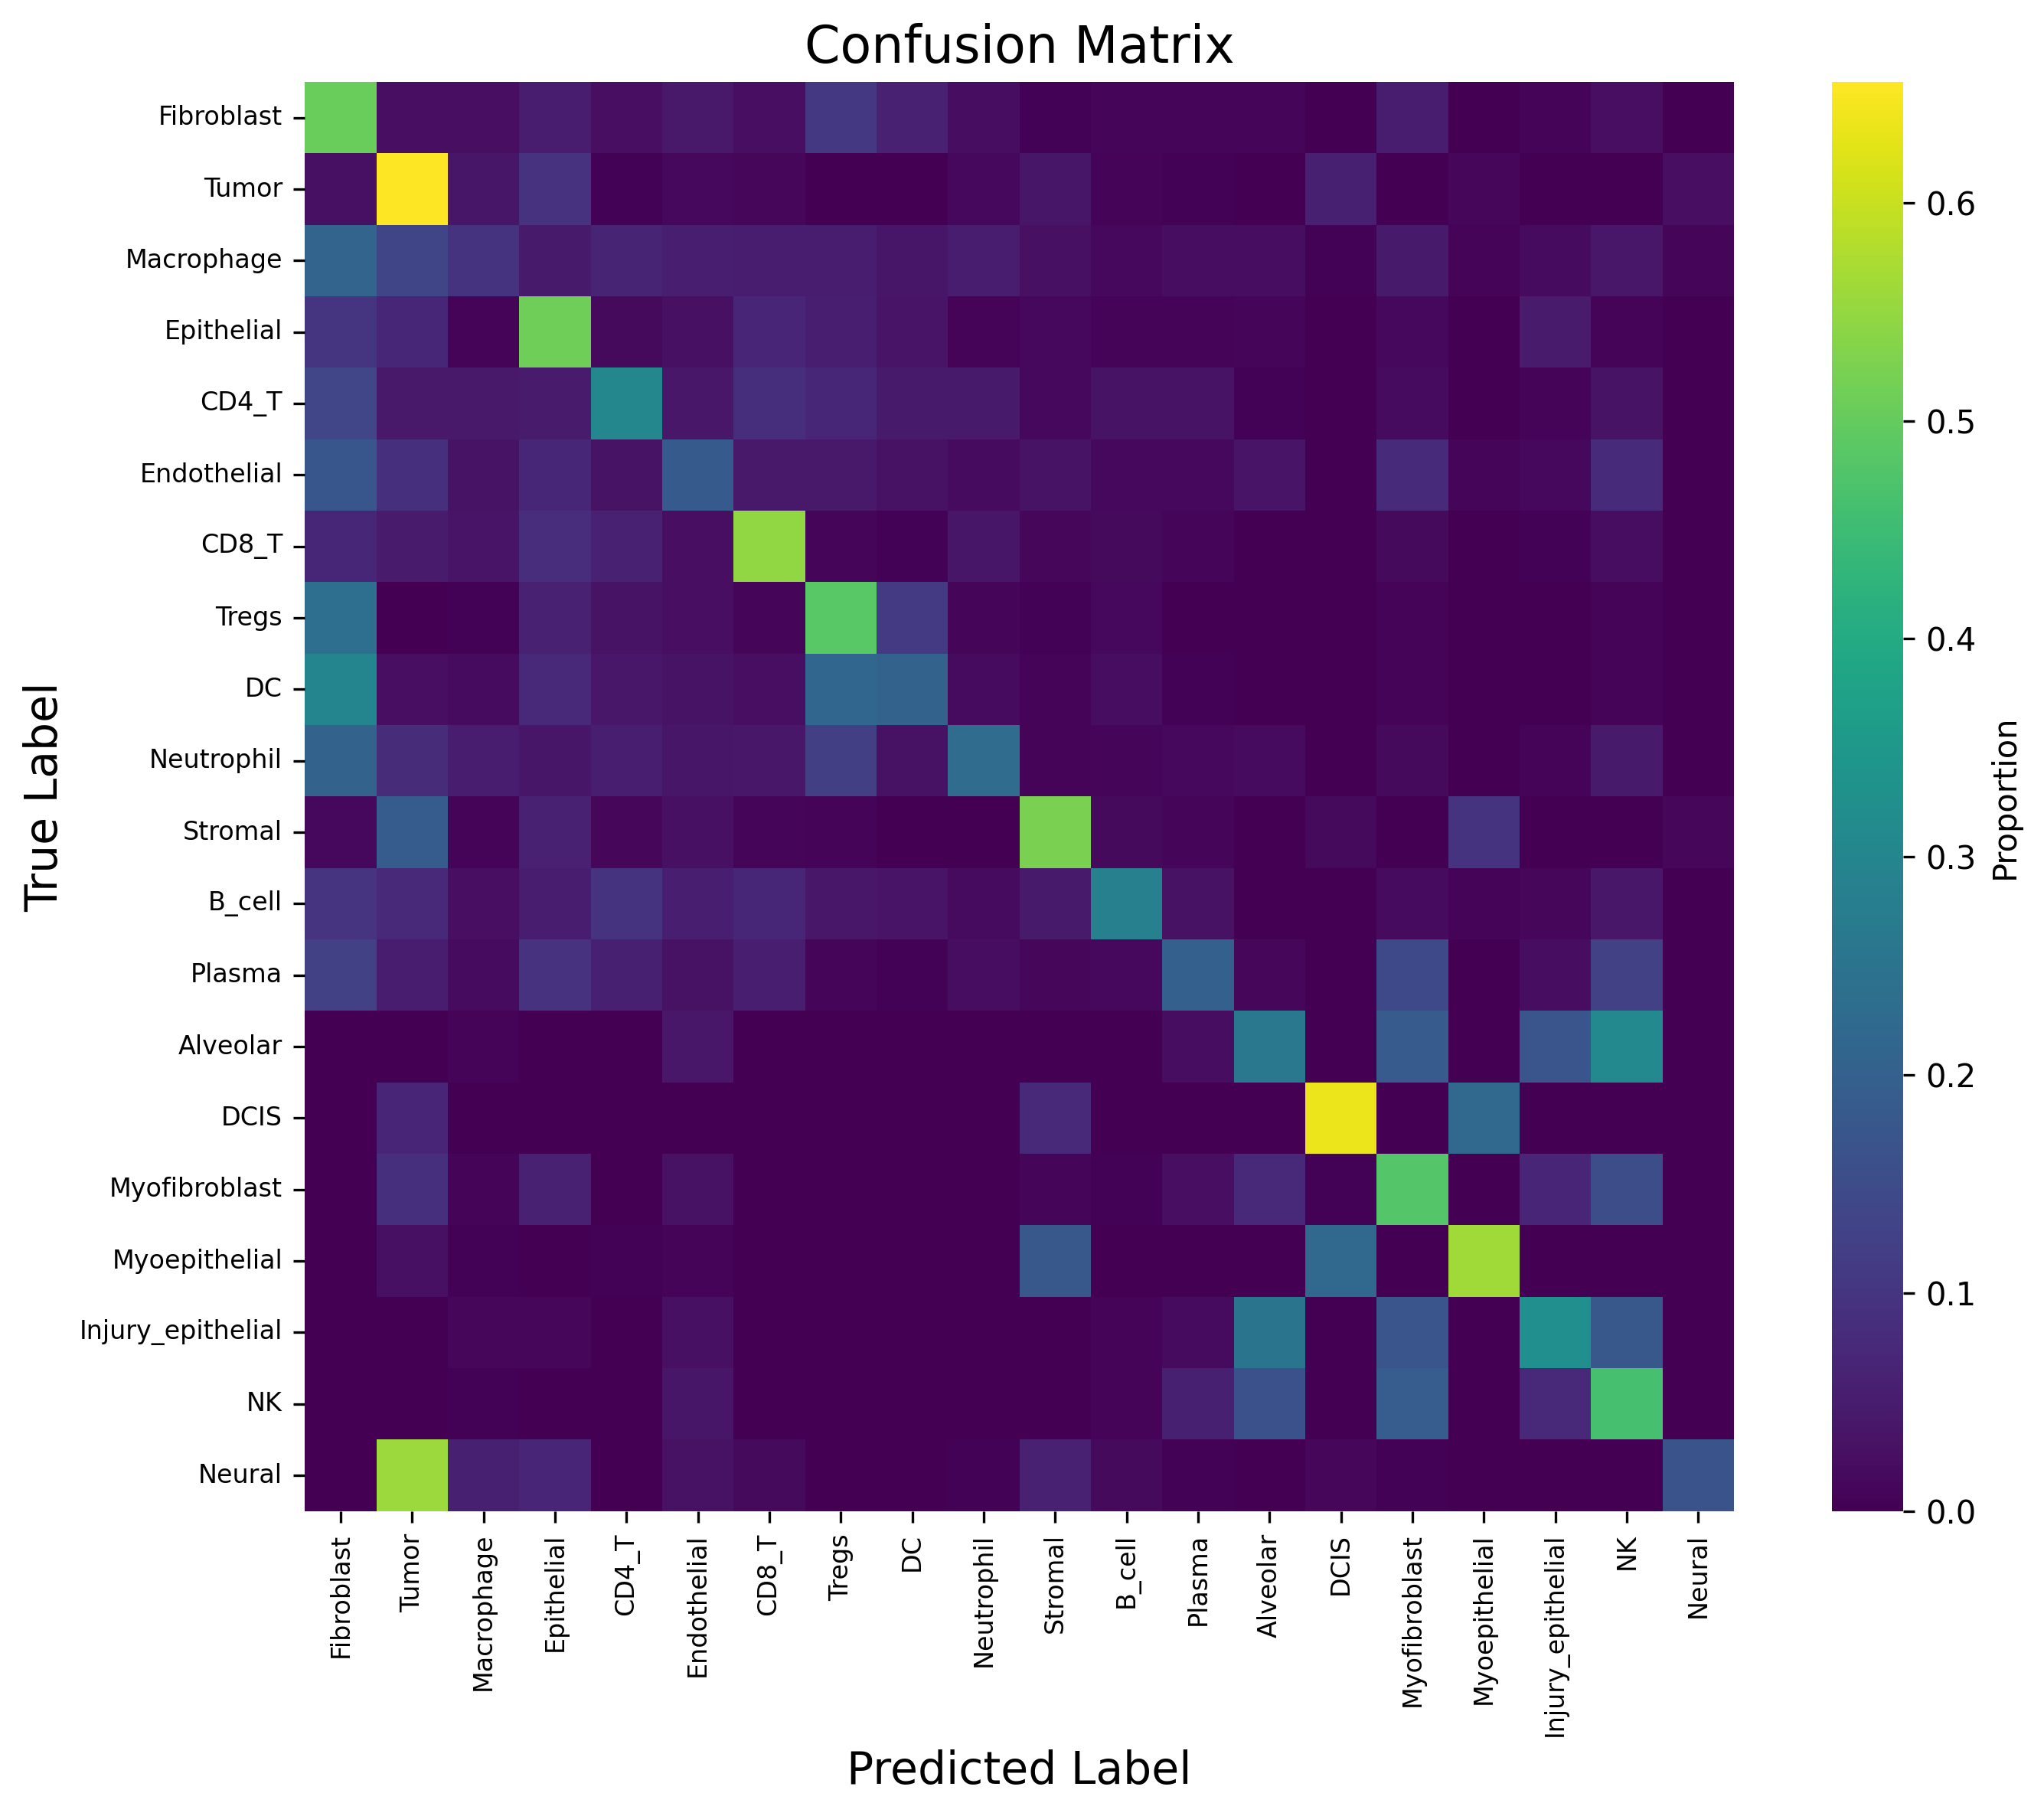

A3 OOF L2 ROC /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/result_uni2_A3_adjacent_spatial_k8mean_gate_paired_v2_seed42/roc_internal_level2_oof.png


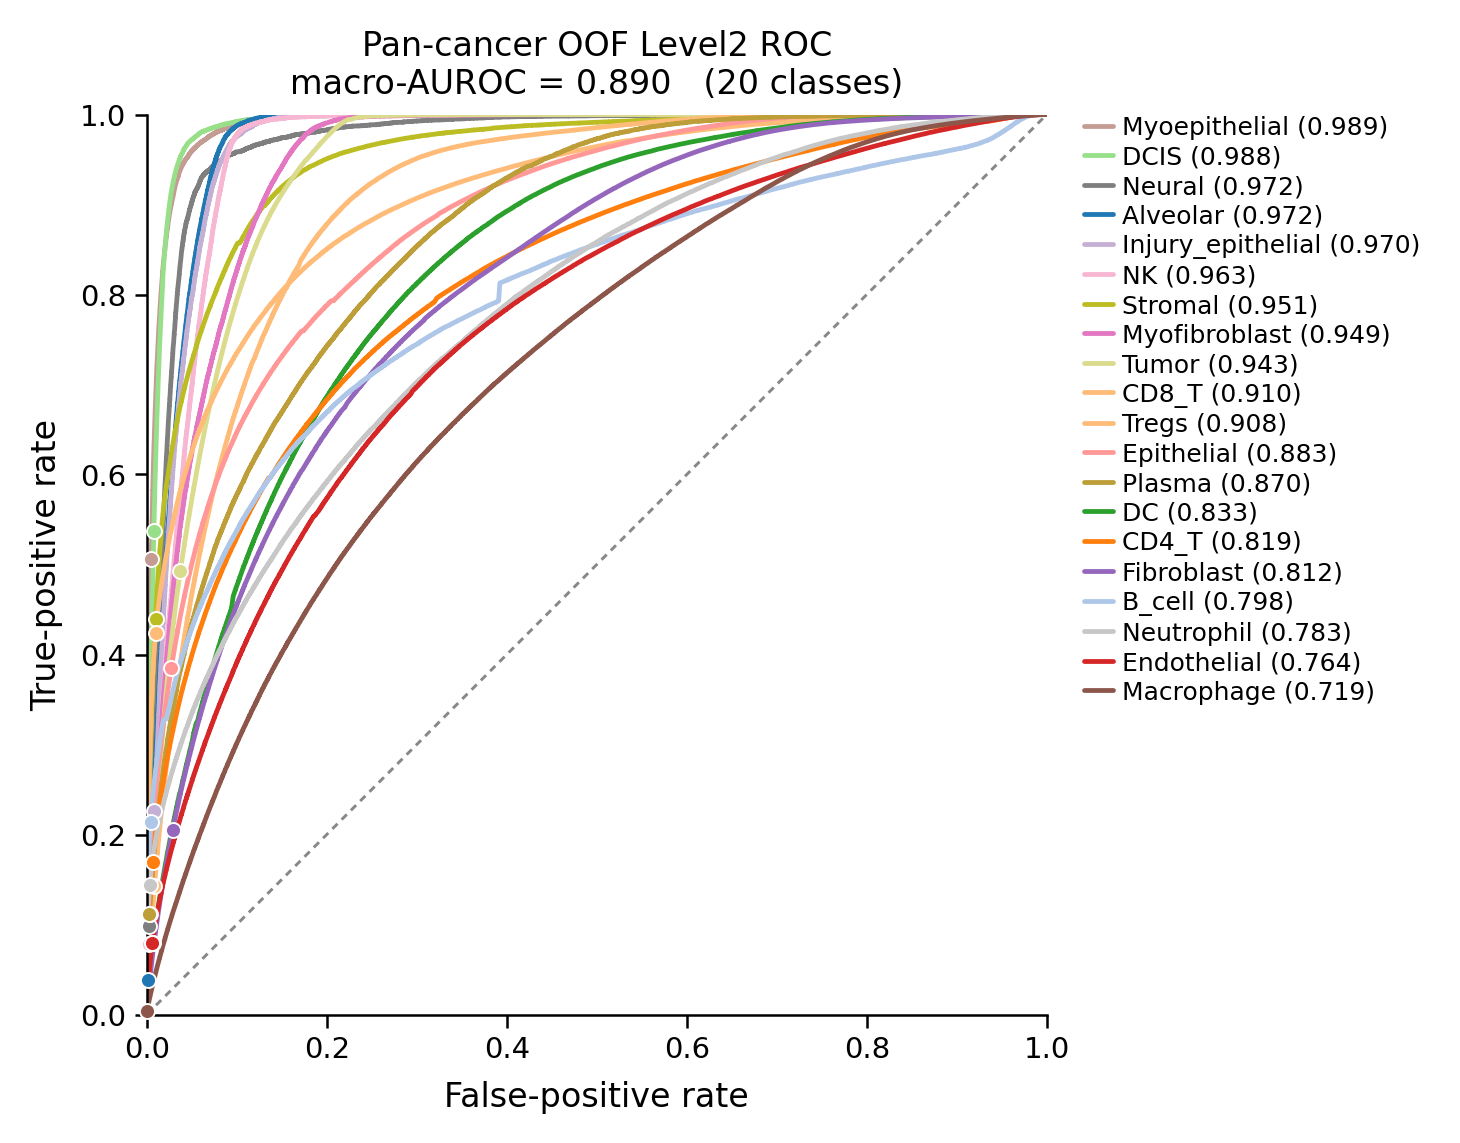

A3 OOF L2 confusion /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/result_uni2_A3_adjacent_spatial_k8mean_gate_paired_v2_seed42/conf_matrix_level2.png


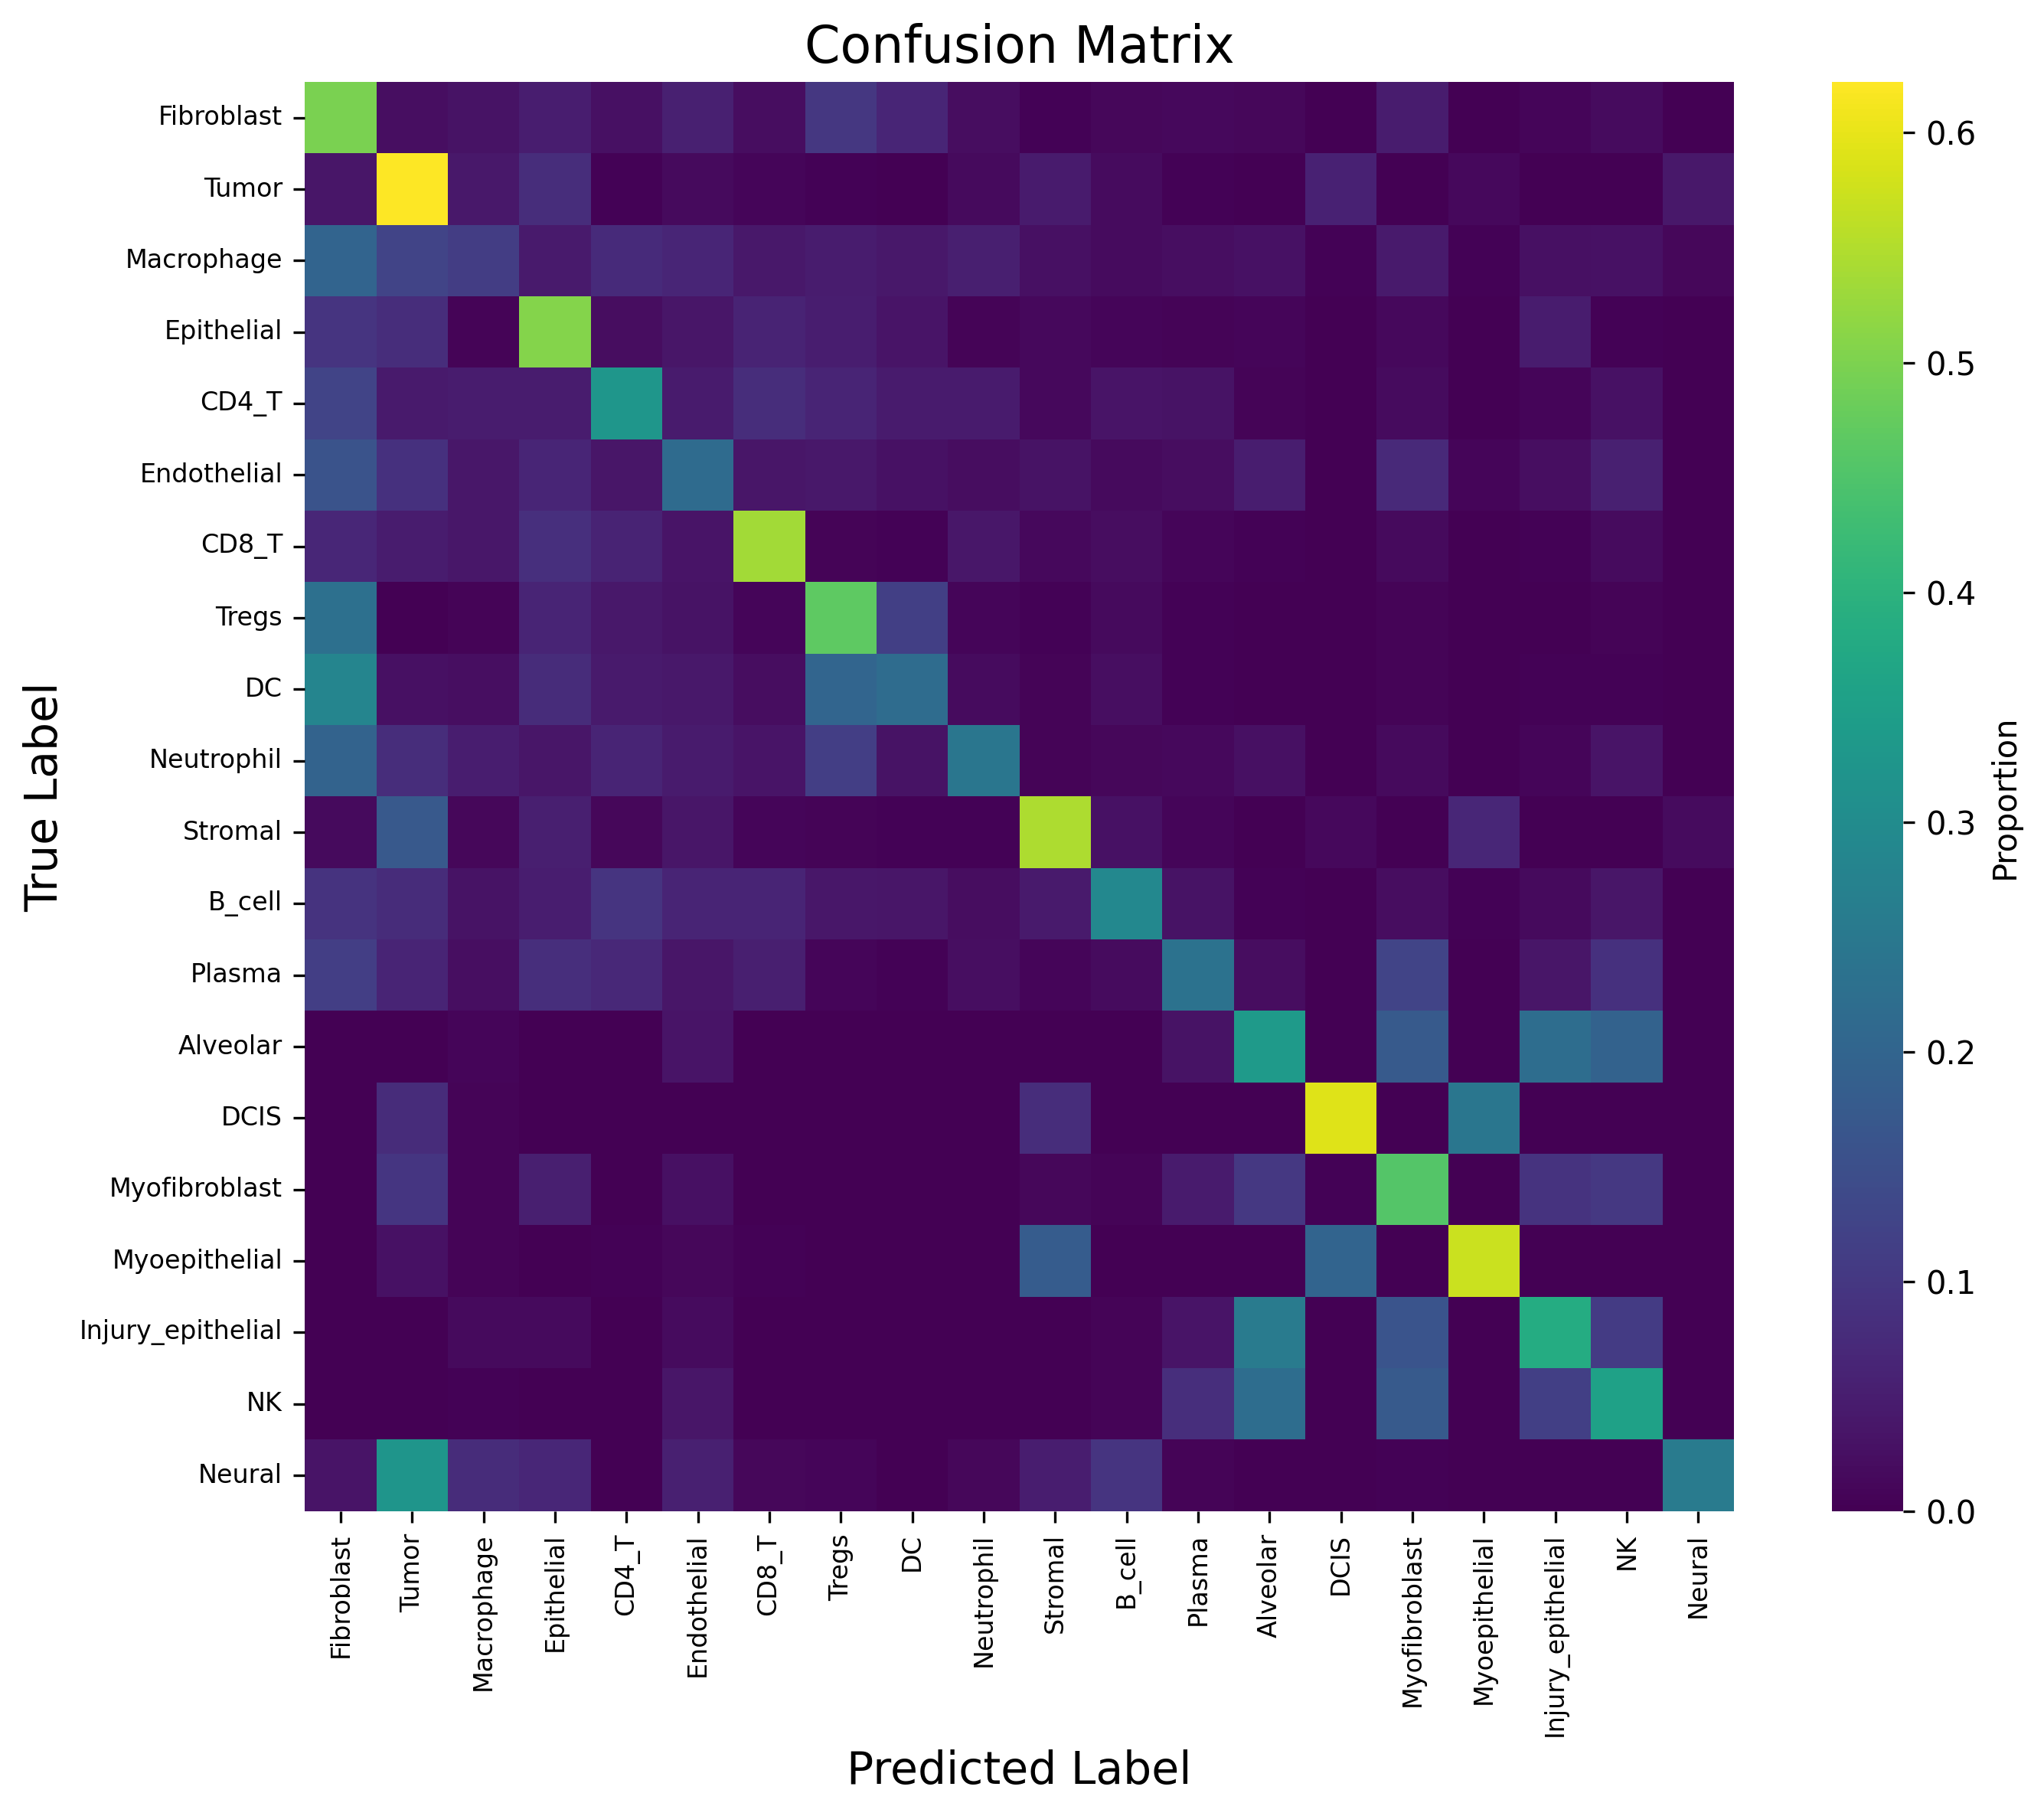

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from pred_statistic_visual import fold_csv, load_folds

PAN_DATA = REPO / "data" / "PanCancer"
OUT_AB = PAN_DATA / ("uni2_ablation_compare_" + os.environ.get("RUN_SUFFIX", "paired_v2_seed42"))
OUT_AB.mkdir(parents=True, exist_ok=True)

ARCH = {
    "A0": {
        "label": "A0 legacy",
        "color": "steelblue",
        "result": PAN_DATA / "result_uni2_A0_legacy_nospatial",
        "tag": "A0_legacy_nospatial",
    },
    "A1": {
        "label": "A1 adjacent",
        "color": "darkorange",
        "result": PAN_DATA / "result_uni2_A1_adjacent_nospatial",
        "tag": "A1_adjacent_nospatial",
    },
    "A2": {
        "label": "A2 k8 mean",
        "color": "seagreen",
        "result": PAN_DATA / "result_uni2_A2_adjacent_spatial_k8mean",
        "tag": "A2_adjacent_spatial_k8mean",
    },
    "A3": {
        "label": "A3 k8 mean+gate",
        "color": "purple",
        "result": PAN_DATA / "result_uni2_A3_adjacent_spatial_k8mean_gate",
        "tag": "A3_adjacent_spatial_k8mean_gate",
    },
}


# 2026.10.26, use new isolated result paths / 保留旧结果
# 2026.10.27, A4 removed from this notebook
import os
RUN_SUFFIX = os.environ.get("RUN_SUFFIX", "paired_v2_seed42")
for key, spec in ARCH.items():
    spec["result"] = spec["result"].with_name(spec["result"].name + "_" + RUN_SUFFIX)


ready = []
inv_rows = []
for key, spec in ARCH.items():
    ckpt = spec["result"] / "cross_dataset_cv" / spec["tag"]
    metrics_path = spec["result"] / "validation_internal_metrics.csv"
    fold_path = fold_csv(spec)
    has_oof = metrics_path.is_file() and fold_path.is_file()
    inv_rows.append(
        {
            "arch": key,
            "label": spec["label"],
            "best_mlp": (ckpt / "best_mlp_gpu.pt").is_file(),
            "n_fold_ckpt": len(list(ckpt.glob("hce_group_fold_[0-9].pt"))),
            "oof_npz": (spec["result"] / "oof_predictions.npz").is_file(),
            "pooled_oof": has_oof,
        }
    )
    if has_oof:
        ready.append(key)
    else:
        print(f"{key}: pooled OOF not written yet ({metrics_path.name})")
display(pd.DataFrame(inv_rows))
if not ready:
    raise FileNotFoundError("No finished UNI2 OOF result under data/PanCancer/result_uni2_A*")

oof_rows = []
for key in ready:
    row = pd.read_csv(ARCH[key]["result"] / "validation_internal_metrics.csv").iloc[0].to_dict()
    row["arch"] = key
    row["label"] = ARCH[key]["label"]
    oof_rows.append(row)
oof_sum = pd.DataFrame(oof_rows)
cols = [c for c in ("arch", "label", "n_cells", "n_folds", "best_fold", "oof_l2_macro_auc", "cv_l2_macro_f1_mean") if c in oof_sum]
display(oof_sum[cols])
base = float(oof_sum.loc[oof_sum.arch == "A0", "oof_l2_macro_auc"].iloc[0])
for _, row in oof_sum.iterrows():
    print(f"Pooled OOF L2 macro AUROC  {row.arch}={float(row.oof_l2_macro_auc):.4f}  vs A0 {float(row.oof_l2_macro_auc) - base:+.4f}")

folds = load_folds(fold_csv(ARCH[ready[0]]), ready[0])
for key in ready[1:]:
    folds = folds.join(load_folds(fold_csv(ARCH[key]), key))
folds = folds.reset_index()
display(folds)

n_arch = len(ready)
width = 0.8 / n_arch
fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.2), sharey=True)
for ax, metric, title in (
    (axes[0], "L1_auc", "L1 head"),
    (axes[1], "L12_auc", "L12"),
    (axes[2], "L2_auc", "L2"),
):
    x = folds["fold"].to_numpy()
    for i, key in enumerate(ready):
        ax.bar(
            x + (i - (n_arch - 1) / 2) * width,
            folds[f"{key}_{metric}"],
            width=width,
            label=ARCH[key]["label"],
            color=ARCH[key]["color"],
        )
    ax.set_title(f"{title} macro-AUROC")
    ax.set_xlabel("fold")
    ax.set_xticks(list(range(5)))
    ax.set_ylim(0.7, 0.95)
    ax.legend(fontsize=7)
axes[0].set_ylabel("AUROC")
fig.suptitle("Fold OOF macro-AUROC: UNI2 A0–A3", y=1.02)
fig.tight_layout()
fig.savefig(OUT_AB / "fold_oof_auroc_A0_A3.pdf", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(3.7, 3.5))
x = folds["fold"].to_numpy()
for i, key in enumerate(ready):
    ax.bar(
        x + (i - (n_arch - 1) / 2) * width,
        folds[f"{key}_L2_f1"],
        width=width,
        label=ARCH[key]["label"],
        color=ARCH[key]["color"],
    )
ax.set_xticks(list(range(5)))
ax.set_xlabel("fold")
ax.set_ylabel("L2 macro-F1")
ax.set_title("Fold OOF L2 macro-F1")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT_AB / "fold_oof_l2_f1_A0_A3.pdf", dpi=150, bbox_inches="tight")
plt.show()

# 2026.10.27, training writes png / 旧代码按 pdf 文件名去找，这批结果只有 png
for key in ready:
    spec = ARCH[key]
    for title, stem in (("OOF L2 ROC", "roc_internal_level2_oof"), ("OOF L2 confusion", "conf_matrix_level2")):
        path = next((spec["result"] / f"{stem}{suffix}" for suffix in (".png", ".pdf") if (spec["result"] / f"{stem}{suffix}").is_file()), None)
        if path is None:
            print(f"{key} missing {stem}")
            continue
        print(f"{key} {title}", path)
        display(Image(filename=str(path), width=480))


In [ ]:
# import numpy as np

# from pred_statistic_visual import load_ontology_heads, oof_labels, oof_tables, split_old_cache, oof_identity, cached_oof_tables

# CLASS_NAMES = load_ontology_heads(PAN_DATA / "ontology_heads.json")

# split_old_cache(OUT_AB)
# scored = [key for key, spec in ARCH.items() if (spec["result"] / "oof_predictions.npz").is_file()]
# missing = [key for key in ARCH if key not in scored]
# if missing:
#     print("No oof_predictions.npz yet:", ", ".join(missing))
# if "A0" not in scored:
#     raise FileNotFoundError("A0 oof_predictions.npz is required as the label reference")
# ref_labels = oof_labels(ARCH["A0"])
# ref_identity = oof_identity(ARCH["A0"])
# class_parts, dataset_parts = [], []
# for key in scored:
#     spec = ARCH[key]
#     if key != "A0" and not np.array_equal(ref_labels, oof_labels(spec)):
#         raise ValueError(f"{key} OOF L2 labels differ from A0; refuse to compare different cells")
#     if not oof_identity(spec).equals(ref_identity):
#         raise ValueError(f"{key}: cell identities or folds differ from A0")
#     class_path = OUT_AB / f"oof_per_class_{key}.csv"
#     dataset_path = OUT_AB / f"oof_per_dataset_{key}.csv"
#     # 2026.10.26, versioned cache / 旧分癌种表自动失效
#     classes_df, dataset_df = cached_oof_tables(spec, CLASS_NAMES, OUT_AB, key)
#     classes_df = classes_df.copy()
#     dataset_df = dataset_df.copy()
#     classes_df.insert(0, "arch", key)
#     dataset_df.insert(0, "arch", key)
#     class_parts.append(classes_df)
#     dataset_parts.append(dataset_df)

# per_class = pd.concat(class_parts, ignore_index=True)
# per_dataset = pd.concat(dataset_parts, ignore_index=True)
# per_class.to_csv(OUT_AB / "oof_per_class_auroc.csv", index=False)
# per_dataset.to_csv(OUT_AB / "oof_per_dataset_auroc.csv", index=False)

# wide_ds = per_dataset.pivot_table(index=["dataset", "head"], columns="arch", values="macro_auroc")
# for key in scored:
#     if key == "A0":
#         continue
#     wide_ds[f"{key}_minus_A0"] = wide_ds[key] - wide_ds["A0"]
# wide_ds = wide_ds.reset_index()
# display(wide_ds)

# l2_ds = wide_ds.loc[wide_ds["head"] == "L2"].set_index("dataset")
# ax = l2_ds[scored].plot(kind="bar", figsize=(4.8, 3.0), color=[ARCH[k]["color"] for k in scored])
# ax.set_ylim(0.5, 1.0)
# ax.set_ylabel("OOF L2 macro AUROC")
# ax.set_title("Per-dataset OOF L2 macro AUROC")
# ax.legend([ARCH[k]["label"] for k in scored], fontsize=8)
# plt.tight_layout()
# fig = ax.get_figure()
# fig.savefig(OUT_AB / "dataset_oof_l2_auroc_A0_A3.pdf", dpi=150, bbox_inches="tight")
# plt.show()

# for head in ("L2", "L12", "L1"):
#     parts = []
#     for key in scored:
#         sub = per_class.loc[(per_class["arch"] == key) & (per_class["head"] == head), ["class_name", "n_pos", "auroc"]]
#         sub = sub.rename(columns={"auroc": f"auroc_{key}", "n_pos": f"n_pos_{key}"})
#         parts.append(sub)
#     m = parts[0]
#     for sub in parts[1:]:
#         m = m.merge(sub.drop(columns=[c for c in sub.columns if c.startswith("n_pos_")]), on="class_name")
#     for key in scored:
#         if key == "A0":
#             continue
#         m[f"{key}_minus_A0"] = m[f"auroc_{key}"] - m["auroc_A0"]
#     sort_col = "A3_minus_A0" if "A3_minus_A0" in m.columns else "auroc_A0"
#     m = m.sort_values(sort_col, ascending=False)
#     macros = "  ".join(f"{key}={m[f'auroc_{key}'].mean():.4f}" for key in scored)
#     print(f"\n=== {head} per-class OOF AUROC  macro {macros} ===")
#     display(m)
#     fig, ax = plt.subplots(figsize=(8.4, max(3.4, 0.28 * len(m) * max(1, len(scored) / 2))))
#     y = np.arange(len(m))
#     height = 0.8 / len(scored)
#     for i, key in enumerate(scored):
#         ax.barh(
#             y + (i - (len(scored) - 1) / 2) * height,
#             m[f"auroc_{key}"],
#             height=height,
#             label=ARCH[key]["label"],
#             color=ARCH[key]["color"],
#         )
#     ax.set_yticks(y, m["class_name"])
#     ax.set_xlim(0.5, 1.0)
#     ax.set_xlabel("OOF OvR AUROC")
#     ax.set_title(f"{head} per-class OOF AUROC")
#     ax.legend(fontsize=8)
#     fig.tight_layout()
#     fig.savefig(OUT_AB / f"per_class_{head.lower()}_auroc_A0_A3.pdf", dpi=150, bbox_inches="tight")
#     plt.show()
